In [1]:
# Copyright (c) Meta Platforms, Inc. and affiliates.

## Video segmentation and tracking with SAM 3

This notebook demonstrates how to use SAM 3 for interactive video segmentation and dense tracking. It covers the following capabilities:

- **Text prompts**: Using natural language descriptions to segment objects (e.g., "person", "shoe")
- **Point prompts**: Adding positive/negative clicks to segment and refine objects

We use the terms _segment_ or _mask_ to refer to the model prediction for an object on a single frame, and _masklet_ to refer to the spatio-temporal masks across the entire video. 

# <a target="_blank" href="https://colab.research.google.com/github/facebookresearch/sam3/blob/main/notebooks/sam3_video_predictor_example.ipynb">
#   <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
# </a>

In [2]:
using_colab = False

In [3]:
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib scikit-learn
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/sam3.git'

In [4]:
!nvidia-smi

Thu Oct  8 21:41:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.211.01             Driver Version: 570.211.01     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4090        Off |   00000000:21:00.0 Off |                  Off |
|  0%   56C    P8             29W /  450W |   11692MiB /  24564MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Set-up

In this example, we allow running inference either on a single GPU or multiple GPUs.

In [5]:
import os
import sam3
import torch

sam3_root = os.path.join(os.path.dirname(sam3.__file__), "..")

# use all available GPUs on the machine
gpus_to_use = range(torch.cuda.device_count())
# # use only a single GPU
# gpus_to_use = [torch.cuda.current_device()]

/home/hci4090/Desktop/ATG_vision/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/hci4090/anaconda3/envs/sam3/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [6]:
from sam3.model_builder import build_sam3_video_predictor

predictor = build_sam3_video_predictor(gpus_to_use=gpus_to_use)

INFO 2026-10-08 21:41:10,644 3159716 sam3_video_predictor.py: 120: using the following GPU IDs: [0, 1]
INFO 2026-10-08 21:41:10,768 3159716 sam3_video_predictor.py: 136: 


	*** START loading model on all ranks ***


INFO 2026-10-08 21:41:10,769 3159716 sam3_video_predictor.py: 138: loading model on rank=0 with world_size=2 -- this could take a while ...
INFO 2026-10-08 21:41:16,866 3159716 sam3_video_base.py: 354: setting max_num_objects=10000 and num_obj_for_compile=16
INFO 2026-10-08 21:41:20,717 3159716 sam3_video_predictor.py: 140: loading model on rank=0 with world_size=2 -- DONE locally
INFO 2026-10-08 21:41:20,718 3159716 sam3_video_predictor.py: 197: spawning 1 worker processes
/home/hci4090/Desktop/ATG_vision/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.

#### Inference and visualization utils

In [7]:
import glob
import os

import cv2
import matplotlib.pyplot as plt
from sam3.visualization_utils import (
    load_frame,
    prepare_masks_for_visualization,
    render_masklet_frame,
    visualize_formatted_frame_output,
)

# font size for axes titles
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["figure.titlesize"] = 12


def propagate_in_video(predictor, session_id):
    # propagate from frame 0 to the end of the video
    outputs_per_frame = {}
    for response in predictor.handle_stream_request(
        request=dict(
            type="propagate_in_video",
            session_id=session_id,
        )
    ):
        outputs_per_frame[response["frame_index"]] = response["outputs"]

    return outputs_per_frame


def get_video_fps(video_path, default_fps=10.0):
    # Preserve the source FPS for MP4 input; use a configurable default for JPEG folders.
    if isinstance(video_path, str) and video_path.lower().endswith(".mp4"):
        cap = cv2.VideoCapture(video_path)
        fps = cap.get(cv2.CAP_PROP_FPS)
        cap.release()
        if fps and fps > 0:
            return fps
    return default_fps


def export_tracking_video(video_frames, outputs_per_frame, output_path, fps, alpha=0.5):
    # Render the tracked masks and object IDs, then encode the frames as MP4.
    if not video_frames:
        raise ValueError("No video frames were loaded.")

    first_frame = load_frame(video_frames[0])
    height, width = first_frame.shape[:2]
    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height),
    )
    if not writer.isOpened():
        raise RuntimeError(f"Could not open output video: {output_path}")

    try:
        for frame_idx in sorted(outputs_per_frame):
            rgb_frame = load_frame(video_frames[frame_idx])
            rendered_frame = render_masklet_frame(
                rgb_frame,
                outputs_per_frame[frame_idx],
                frame_idx=frame_idx,
                alpha=alpha,
            )
            writer.write(cv2.cvtColor(rendered_frame, cv2.COLOR_RGB2BGR))
    finally:
        writer.release()

    print(f"Saved tracking video to: {os.path.abspath(output_path)}")


### Loading an example video

We assume that the video is stored as either **a list of JPEG frames with filenames like `<frame_index>.jpg`** or **an MP4 video**.

Note that you can extract their JPEG frames using ffmpeg (https://ffmpeg.org/) as follows:
```
ffmpeg -i <your_video>.mp4 -q:v 2 -start_number 0 <output_dir>/'%05d.jpg'
```
where `-q:v` generates high-quality JPEG frames and `-start_number 0` asks ffmpeg to start the JPEG file from `00000.jpg`.

In [ ]:
# "video_path" needs to be either a JPEG folder or a MP4 video file
video_path = f"{sam3_root}/assets/videos/palace.mp4"

In [9]:
# load "video_frames_for_vis" for visualization purposes (they are not used by the model)
if isinstance(video_path, str) and video_path.endswith(".mp4"):
    cap = cv2.VideoCapture(video_path)
    video_frames_for_vis = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        video_frames_for_vis.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
else:
    video_frames_for_vis = glob.glob(os.path.join(video_path, "*.jpg"))
    try:
        # integer sort instead of string sort (so that e.g. "2.jpg" is before "11.jpg")
        video_frames_for_vis.sort(
            key=lambda p: int(os.path.splitext(os.path.basename(p))[0])
        )
    except ValueError:
        # fallback to lexicographic sort if the format is not "<frame_index>.jpg"
        print(
            f'frame names are not in "<frame_index>.jpg" format: {video_frames_for_vis[:5]=}, '
            f"falling back to lexicographic sort."
        )
        video_frames_for_vis.sort()

### Opening an inference session on this video

SAM 3 requires stateful inference for interactive video segmentation, so we need to initialize an **inference session** on this video.

During initialization, it loads all the video frames and stores their pixels in the session state.

In [10]:
response = predictor.handle_request(
    request=dict(
        type="start_session",
        resource_path=video_path,
    )
)
session_id = response["session_id"]

frame loading (OpenCV) [rank=0]: 100%|██████████| 237/237 [00:01<00:00, 169.39it/s]
INFO 2026-10-08 21:41:38,260 3176477 sam3_base_predictor.py: 158: started new session 35dd79ec-8cbd-44f2-b3f3-15183b2fd5fc
INFO 2026-10-08 21:41:38,641 3159716 sam3_base_predictor.py: 158: started new session 35dd79ec-8cbd-44f2-b3f3-15183b2fd5fc


### Video promptable concept segmentation with text

Using SAM 3 you can describe objects using natural language, and the model will automatically detect and track all instances of that object throughout the video.

In the example below, we add a text prompt on frame 0 and propagation throughout the video. Here we use the text prompt "person" to detect all people in the video. SAM 3 will automatically identify multiple person instances and assign each a unique object ID.

Note that the first call might be slower due to setting up buffers. **You can rerun all the cells below when measuring speed.**

In [11]:
# note: in case you already ran one text prompt and now want to switch to another text prompt
# it's required to reset the session first (otherwise the results would be wrong)
_ = predictor.handle_request(
    request=dict(
        type="reset_session",
        session_id=session_id,
    )
)

[Gloo] Rank 1 is connected to 1[Gloo] Rank  peer ranks. Expected number of connected peer ranks is : 1
0 is connected to 1 peer ranks. Expected number of connected peer ranks is : 1


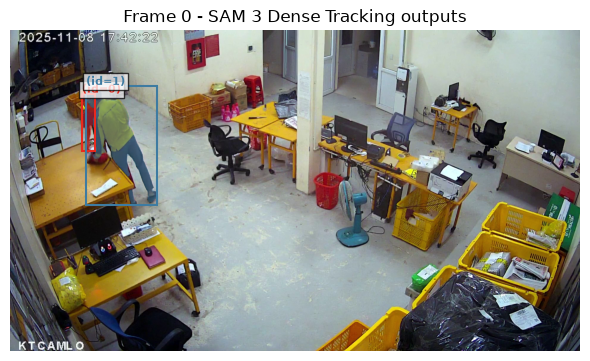

In [12]:
prompt_text_str = "person"
frame_idx = 0  # add a text prompt on frame 0
response = predictor.handle_request(
    request=dict(
        type="add_prompt",
        session_id=session_id,
        frame_index=frame_idx,
        text=prompt_text_str,
    )
)
out = response["outputs"]

plt.close("all")
visualize_formatted_frame_output(
    frame_idx,
    video_frames_for_vis,
    outputs_list=[prepare_masks_for_visualization({frame_idx: out})],
    titles=["SAM 3 Dense Tracking outputs"],
    figsize=(6, 4),
)

propagate_in_video:   0%|          | 0/237 [00:00<?, ?it/s]

INFO 2026-10-08 21:41:58,173 3176477 sam3_base_predictor.py: 317: propagation ended in session 35dd79ec-8cbd-44f2-b3f3-15183b2fd5fc


propagate_in_video: 0it [00:00, ?it/s]

INFO 2026-10-08 21:41:58,226 3159716 sam3_base_predictor.py: 317: propagation ended in session 35dd79ec-8cbd-44f2-b3f3-15183b2fd5fc


Saved tracking video to: /home/hci4090/Desktop/ATG_vision/sam3/examples/sam3_person_tracking_output.mp4


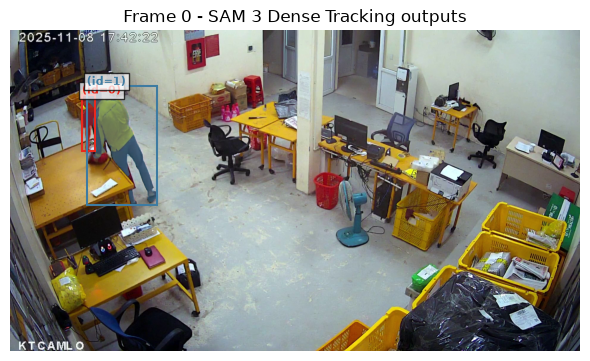

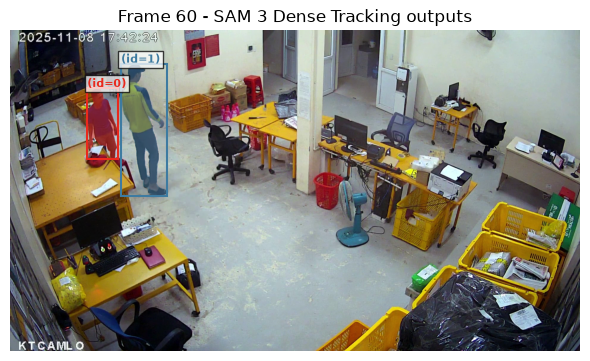

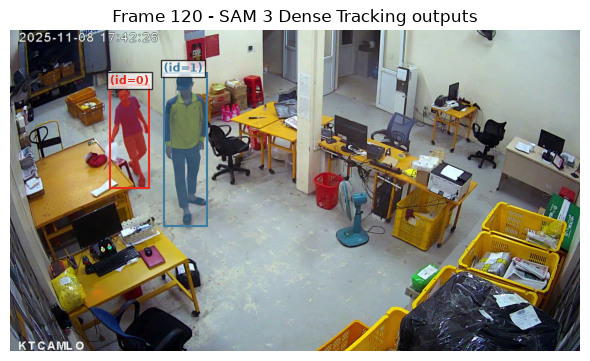

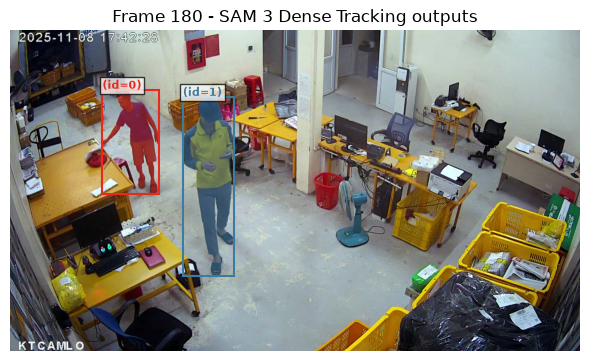

In [13]:
# now we propagate the outputs from frame 0 to the end of the video and collect all outputs
outputs_per_frame = propagate_in_video(predictor, session_id)

# export the tracking result as an MP4 before formatting mutates the output dictionary
output_video_path = "sam3_person_tracking_output.mp4"
export_tracking_video(
    video_frames_for_vis,
    outputs_per_frame,
    output_video_path,
    fps=get_video_fps(video_path),
)

# finally, we reformat the outputs for visualization and plot the outputs every 60 frames
outputs_per_frame = prepare_masks_for_visualization(outputs_per_frame)

vis_frame_stride = 60
plt.close("all")
for frame_idx in range(0, len(outputs_per_frame), vis_frame_stride):
    visualize_formatted_frame_output(
        frame_idx,
        video_frames_for_vis,
        outputs_list=[outputs_per_frame],
        titles=["SAM 3 Dense Tracking outputs"],
        figsize=(6, 4),
    )

### Close session

Each session is tied to a single video. We can close the session after inference to free up its resources.

(Then, you may start a new session on another video.)

In [14]:
# finally, close the inference session to free its GPU resources
# (you may start a new session on another video)
_ = predictor.handle_request(
    request=dict(
        type="close_session",
        session_id=session_id,
    )
)

INFO 2026-10-08 21:42:04,917 3176477 sam3_base_predictor.py: 421: removed session 35dd79ec-8cbd-44f2-b3f3-15183b2fd5fc
INFO 2026-10-08 21:42:05,084 3159716 sam3_base_predictor.py: 410: empty_cache freed 5769265152 bytes (free_pct 5.5% -> 28.3%, reserved 10986979328 -> 5217714176 bytes)
INFO 2026-10-08 21:42:05,084 3159716 sam3_base_predictor.py: 421: removed session 35dd79ec-8cbd-44f2-b3f3-15183b2fd5fc


### Clean-up

After all inference is done, we can shutdown the predictor to free up the multi-GPU process group.

In [15]:
# after all inference is done, we can shutdown the predictor
# to free up the multi-GPU process group
predictor.shutdown()

INFO 2026-10-08 21:42:05,116 3159716 sam3_video_predictor.py: 333: shutting down 1 worker processes
INFO 2026-10-08 21:42:05,117 3176477 sam3_video_predictor.py: 305: worker rank=1 shutting down
INFO 2026-10-08 21:42:05,419 3159716 sam3_video_predictor.py: 339: shut down 1 worker processes
